In [1]:
# ============================================================
# Notebook setup
# ============================================================

%load_ext autoreload
%autoreload 2

# Control figure size
figsize=(14, 4)

from util import util
from matplotlib import pyplot as plt
import numpy as np
import seaborn as sn
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GridSearchCV
import xgboost
from sklearn.inspection import permutation_importance
import shap
import pickle
import os
from boruta import BorutaPy

# Generate synthetic data
data, name_map = util.generate_data(size=500, seed=42)
num_cols = [c for c in data.columns[:-1] if len(data[c].unique()) > 2]
cat_cols = [c for c in data.columns[:-1] if len(data[c].unique()) == 2]

# Data pre-processing
X, y = data[data.columns[:-1]].copy(), data[data.columns[-1]].copy()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

# Train a GBT model
base_est = xgboost.XGBClassifier(tree_method='hist', importance_type='total_gain')
param_grid={'max_depth': [2, 3, 4], 'n_estimators': list(range(20, 41, 5)), 'reg_lambda': np.linspace(0, 500, 6)}
gscv = GridSearchCV(base_est, param_grid=param_grid)
gscv.fit(X, y)
xbm, xbm_params = gscv.best_estimator_, gscv.best_params_

# Retrieve SHAP values
with open(os.path.join('..', 'data', 'shap_values.pickle'), 'rb') as fp:
    shap_values = pickle.load(fp)

# All Relevant Feature Selection

## Racapping Our Path So Far

**We started with a somewhat clear goal**

* Given data containing candidate correlates and a discrete target
* ...We aimed at identifying the most relevant correlates

**We applied a baseline approach (Lasso) to:**

* Obtain a surrogate for our data-generation process
* Analyze the impact of each candidate correlate (feature)
* Identify the most relevant correlates

**Our baseline turned out to be largely insufficient, so we:**

* Trained a non-linear model to obtain a more reliable surrogate
* Learn to assess importance via a permutation-based method
* Learned to explain individual examples via SHAP

**We still have a couple of major open problems...**

## Open Problems

**There's a mistmatch between local and global explanations**

* We are using SHAP to assess local feature effects 
* ...And permutation importance for global feature effects

As a side effect, there may be inconsistences in our analysis

**We still don't know how to identify the most relevant features**

* Like in the Lasso appproach we could think of using a threshold
* ...But we still don't know how such threshold should be calibrated

> **It's time that we fix both of them**

## Global Feature Analysis via SHAP

**SHAP explanations can be aggreated to get global importance scores**

By default, this is done by averaring absolute SHAP values:

$$
\bar{\phi}_j(x) = \frac{1}{n} \sum_{i=1}^m |\phi_j(x_i)|
$$

* Other aggregation functions can also be used (e.g. max)

**By using aggregated SHAP scores**

...We can attempt to identify the most important correlates

* I.e. we can used SHAP scores like we were using permutation importances
* In fact, both approaches are sound and well defined

## Global Feature Analysis via SHAP

**The SHAP library provide convenience functions to plot aggregated values**

Here's how to plot mean (absolute) SHAP values:

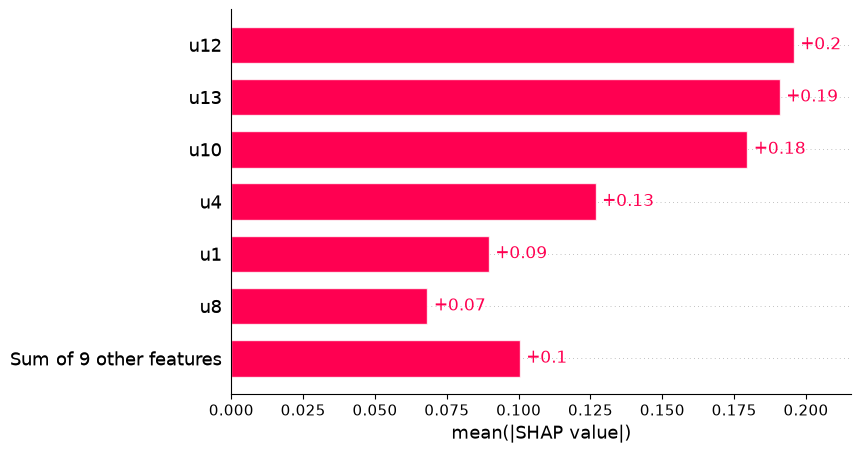

In [2]:
shap.plots.bar(shap_values, max_display=7)

## Global Feature Analysis via SHAP

**The SHAP library provide convenience functions to aggregated values**

Here's how to display the maximum (absolute) SHAP values:

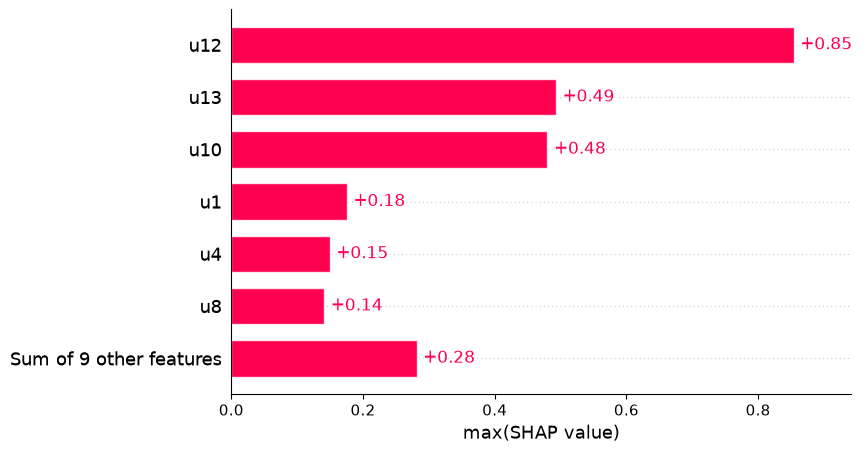

In [3]:
shap.plots.bar(shap_values.max(0), max_display=7)

## Semantics for Feature Selection

**A viable approach for feature selection consists in solving:**

$$
\mathop{\mathrm{argmin}}_{\mathcal{S} \subseteq \mathcal{X}} \left\{ |\mathcal{S}| : L\left(y, \hat{y}\right) \leq \theta \text{ with: } \hat{y} = \hat{f}_{\mathcal{S}}\left(x_{\mathcal{S}}\right) \right\}
$$

Where $x, y$ denote all the training data. Intuitively:

* We search for the smallest subset of features $\mathcal{S}$
* ...Such that a model $\hat{f}_{\mathcal{S}}$ trained over only over them
* ...Still has an acceptable (cross-validation) accuracy

Heuristics (e.g. greedy search) can be used to improve scalability

**This optimization-driven approach**

* ...Can be customized by adjusting the constraint and cost function
* ...Can reduce data storage and location costs on the deployed model

## Semantics for Feature Selection

**If we care just about _cost and accuracy_, the optimization approach is perfect**

> **But it is not suitable for our current case study...<br> Can you tell why?**

**For a number of reasons:**

* We care about finding _all the relevant features_, not a minimal set
* How should the accuracy threshold be calibrated?
* What about the noise induced by retraining?

If we wish to use ML for data analysis, we need another approach

**...In particular, we will rely on _statistical hypothesis testing (HT)_**

## Statistical Hypothesis Testing

**HT builds evidence for a hypothesis by _refuting_ a competing one:**

We start with:

- a random variable $X$
- a hypothesis $H(X)$

We define:

- a competing _null hypothesis_ $H_0(X)$
- a experimental statistics $T(X)$, linked to $H_0$

**In most cases:**

* $H_0$ is an attempt to negate our original hypothesis
* $T(X)$ is such that some of its values are _unlikely_ under $H_0$

## Statistical Hypothesis Testing

**We reject the null hypothesis by checking what happens _when $H_0$ is true_**

In particular, we need to:

* Compute the distribution of $T(X)$ under $H_0$, i.e. $P(T \mid H_0)$ _in the general case_
* Compute the value $t$ of $T(X)$ under $H_0$ _on our sample_

**Then we look at the _$p$-value $P(t \mid H_0)$_:**

* This is the probability of observing $t$, assuming $H_0$ is true
* If $p$ is small enough, we reject $H_0$
* ...Which in turn provides support for our original hypothesis

**Sometimes, only high/small values of $T$ support the hypothesis**

* In that case, we say we have a "single tailed" test
* ...And we need to be slightly more careful when computing the $p$-value

<div class=big>
    <small>This is probably very confusing...</small><br>
    Let's make an example for our case
</div>

## Hypothesis, Data, and Null-Hypothesis

**First, we need to define our _variable_ and _hypothesis_**

We care about identifying correlates, so a possible choice might be:

* The variable will be the pair $(X, Y)$, i.e. observable and target
* $H \equiv \text{$X$ is correlated with $Y$, according to a score $r$}$

**Now we need a competing _null hypothesis_**

A good choice might be $H_0 \equiv \text{``$X$ is actually uncorrelated''}$

* In this case, refuting $H_0$ lends directly support for $H$
* Other situations might be more complicated

> **The real difficulty is defining the _test statistics_ $T$**

## Towards a Test Statistics

**Let's consider our situation:**

* Given a sample $(\mathbf{x}, \mathbf{y}) = \{x_i, y_i\}_i$
* ...We can compute the importance score $r(\mathbf{x}, \mathbf{y})$

We can use any correlation or importance score

**We can simulate the effect of lack of correlation**

...By simply shuffling the values in $\mathbf{x}$

* By doing so, we preserve the distribution of $X$
* ...While breaking any correlation with $Y$

**Let $\mathbf{\tilde{x}}$ refer to the result of one such shufflings**

## Towards a Test Statistics

**Now, let's consider:**

$$
E(\mathbf{x}, \mathbf{\tilde{x}}, \mathbf{y}) = \left\{\begin{aligned}
1 && \text{if } r(\mathbf{x}, \mathbf{y}) \geq r(\mathbf{\tilde{x}}, \mathbf{y}) \\
0 && \text{otherwise}
\end{aligned}\right.
$$

* Both $\mathbf{x}$ and $\mathbf{\tilde{x}}$ are drawn from random variables
* Hence, $E(\mathbf{x}, \mathbf{\tilde{x}}, \mathbf{y})$ will also be random
* ...And it will follow a _Bernoulli distribution_

**Then, using $E$ as a shorthand for $E(\mathbf{x}, \mathbf{\tilde{x}}, \mathbf{y})$**

* If there is no correlation, then $E = 1$ will occur roughly half of the times

$$P(E = 1 \mid H_0) = \frac{1}{2}$$

* If there is a correlation, the number will be _higher_

## Towards a Test Statistics

**We can obtain our statistics by repeating this experiment:**

We shuffle $m$ times, and count _how often we get $E = 1$_

$$
T[\mathbf{x}, \mathbf{y} \mid H_0] \equiv \sum_{i = 1}^m E(\mathbf{x}, \mathbf{\tilde{x}}, \mathbf{y}) \quad \text{ with $\mathbf{\tilde{x}}$ randomly shuffled}
$$

* All experiments are independent, so $T$ follows a _Binomial distribution_
* Hence, the full idistribution for $T$ is $B(m, {^1/_2})$

**Now:**

* If we observe a count higher than expected, $H_0$ is probably false
* Otherwise, we can conclude nothing

## Theoretical Probability Computation

**This is how the distribution looks like in practice**

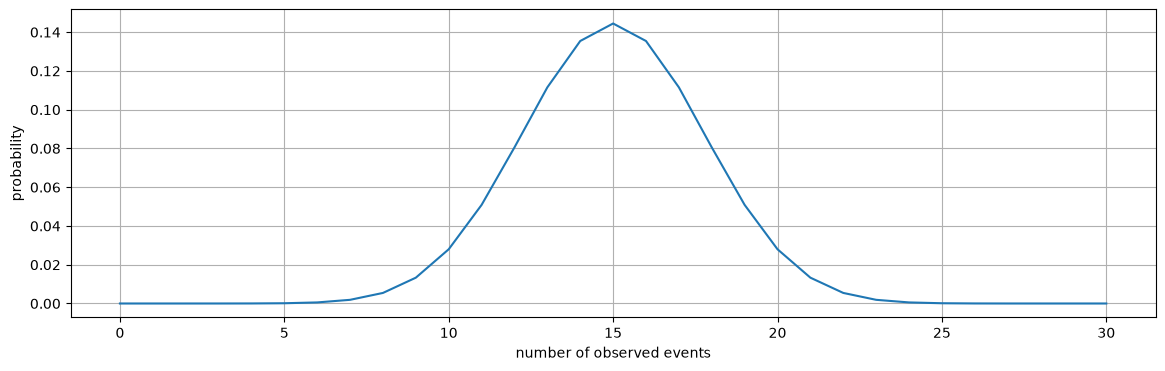

In [9]:
util.binomial_plot(n=30, p=0.5, figsize=figsize)

* This tells us how likely we are to observe a certain number of $E = 1$ events
* ...Assuming that the null hypothesis $H_0$ is true

## $p$-value and Rejection Region

**Any sufficiently _high_ value of $T[\mathbf{x}, \mathbf{y} \mid H_0]$ supports the hypothesis**

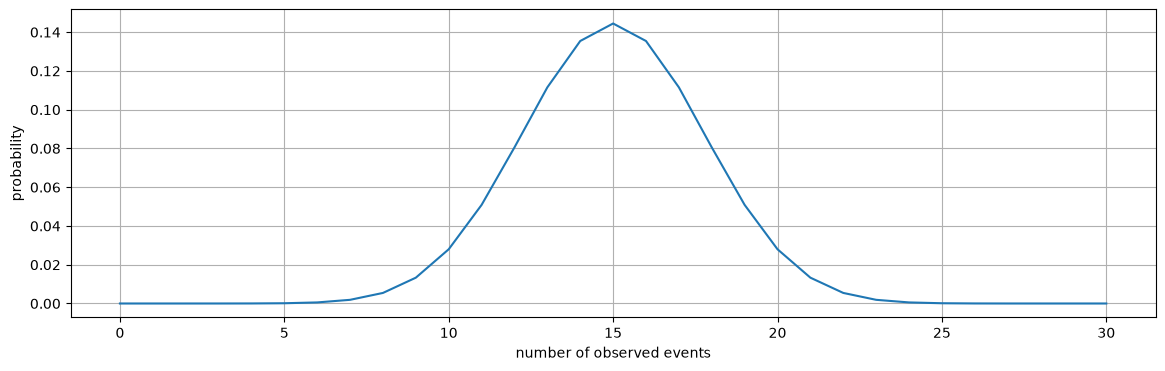

In [10]:
util.binomial_plot(n=30, p=0.5, figsize=figsize)

* Let $t$ be the value of $T[\mathbf{x}, \mathbf{y} \mid H_0]$ we obtained
* If $t$ is the right tail, we consider its probability $P(T = t \mid H_0)$

## $p$-value and Rejection Region

**Any sufficiently _high_ value of $T[\mathbf{x}, \mathbf{y} \mid H_0]$ supports the hypothesis**

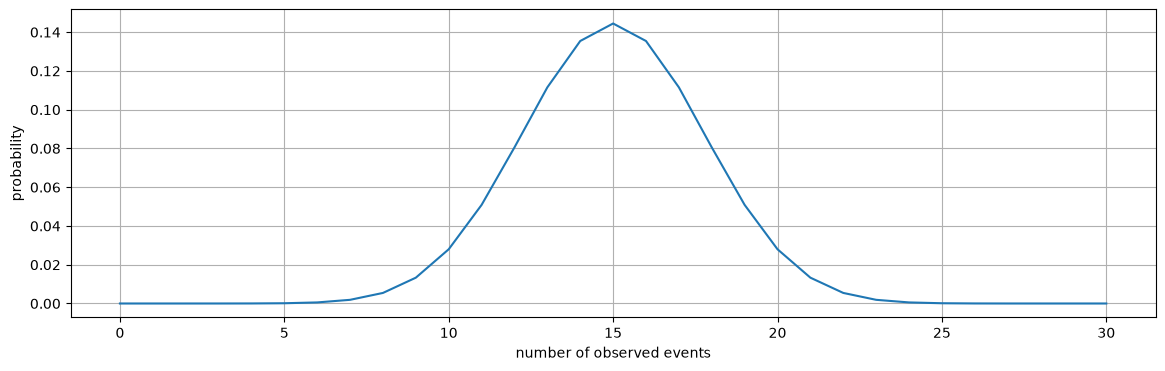

In [10]:
util.binomial_plot(n=30, p=0.5, figsize=figsize)

$P(T = t \mid H_0)$ is our $p$-value, i.e. probability of the outcome under $H_0$

* If $P(T = t \mid H_0) \leq 1 - \alpha$ for a confidence value $\alpha$
* ...Then we can _reject the null hypothesis_

## $p$-Value and the Statistical Test

**Basically, there is a _rejection region_ in the distribution**

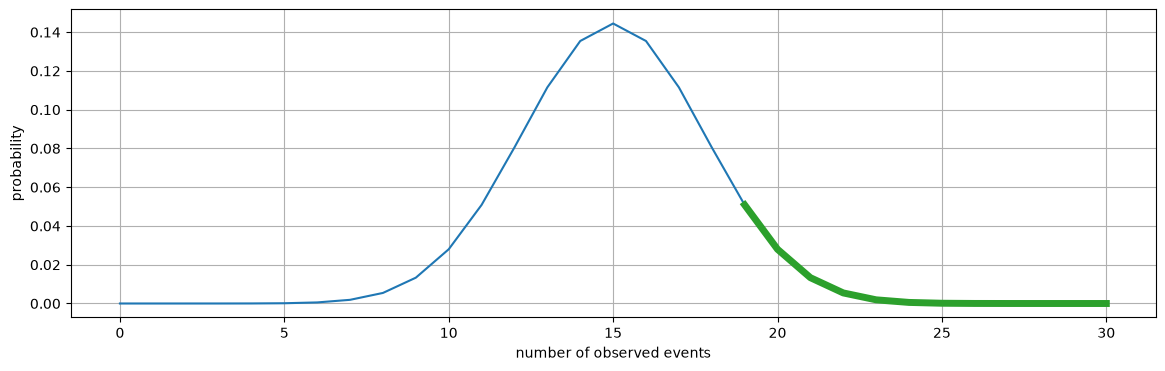

In [11]:
util.binomial_plot(n=30, p=0.5, r_alpha=0.05, figsize=figsize)

* For a chosen confidence level, e.g. 95%
* If $t$ falls in the region, then we can reject $H_0$

## Boruta

**The approach we have just seen is the backbone of [the Boruta algorithm](https://www.jstatsoft.org/article/view/v036i11)**

* The Boruta algorithm is a SotA feature selection method
* ...That relies in statistical HT to determine relevant features

**Like in our analysis, the method relies on surrogate models**

...And in particular on tree ensembles (the name refers to [a Slavic forest spirit](https://en.wikipedia.org/wiki/Devil_Boruta))

* As a consequence, the algorithm can deal with non-linear correlations
* ...And accounts for interactions between multiple features

**Boruta is an all-relevant feature selector**

* This makes it particularly well suited for scientific analyses
* ...But it can be used to reduce data collection costs or improve generalization

## Tested Hypothesis in Boruta

**Boruta relies on a measure of feature importance**

* The original algorithm and the [BorutaPy package](https://github.com/scikit-learn-contrib/boruta_py) use permutation importance
* An unmaintained [version based on SHAP](https://github.com/Ekeany/Boruta-Shap) is also available

In both cases, importance is computed w.r.t. a reference dataset

**The hypothesis $H$ being tested is a bit more general than ours:**

> "Attribute $j$ is important _among those in the dataset_, according to the chosen metric"

* The main difference is that we consider now _multiple features_
* ...Which calls for slighly more sophisticated test statistics

## Test Statistics in Boruta

**The main idea is still to rely on permuted features**

Let $(\mathbf{x}, \mathbf{y})$ be our dataset, with each $x_i$ being a vector

* First, we introduce shuffled versions $\tilde{x}$ _of all attributes_
* These are called _shadow features_ by the algorithm. Let their values be $\tilde{x}$

Then, we train a predictive model on $(x, \tilde{x}, y)$

**Let $\phi_j((\mathbf{x},\mathbf{\tilde{x}}), \mathbf{y})$ be the importance of feature $j$, on the augmented dataset**

* If the feature is important, its $\phi_j$ should beat _all_ the shadow features
* Therefore, we can consider the event $E$

$$
\phi_j((\mathbf{x}, \mathbf{\tilde{x}}), y) > \max_{j \text{ is shadow}} \phi_j((\mathbf{x}, \mathbf{\tilde{x}}), y)
$$

## Test Statistics in Boruta

**Then the testing statistics $T$ is similar to the one we used:**

* The algorithms performs multiple experiments (retraining the model)
* ...And counts the number of times the event is satisfied ("hits")

**The thereotical distribution for $T$ under $H_0$ is _mostly_ a binomial**

* The algorithm needs to apply a statistical correction
* ...Since we are testing multiple features together (we have a $\max$)

**Boruta tests both for correlation and lack of correlation**

* Some features will be _confirmed important_
* Some features will be _confirmed unimportant_
* Some features will be remain _tentative_

## Using Boruta in Practice

**We'll use Boruta through the BorutaPy package**

In [11]:
bfs = BorutaPy(xbm, n_estimators='auto', max_iter=100, verbose=0, random_state=42)
bfs.fit(X=X, y=y);

* We can choose how many samples to use
* The algorithm also determines the best number of estimators

**Let's see which features have been selected**

In [16]:
print('Confirmed important:', [s for s in X.columns[bfs.ranking_ == 1].values])
print('Uncomfirmed:', [s for s in X.columns[bfs.ranking_ == 2].values])
print('Confirmed unimportant:', [s for s in X.columns[bfs.ranking_ > 2].values])

Confirmed important: ['u1', 'u10', 'u12', 'u13']
Uncomfirmed: ['u4']
Confirmed unimportant: ['u0', 'u2', 'u3', 'u5', 'u6', 'u7', 'u8', 'u9', 'u11', 'u14']


<div class=big>
Ok, but... Did it work?<br>
</div>

## What we Have Discovered

**So far, by using Boruta we found that:**

* There seem to be 4 relevant features, i.e. $U_1, U_{10}, U_{12}, U_{13}$

**By inspecting the data we found that:**

* $U_{12}$ and $U_{13}$ are roughly Normally distributed
* $U_1$ is not Normally distributed
* $U_{10}$ is binary

**By using SHAP we found that:**

* $U_{13}$ has a mostly monotonic effect
* $U_{12}$ has a complex effect, which seems to be modulated by $U_{10}$
* $U_1$ seems to have mostly an anti-monotonic effect

<div class=big>
We can now inspect the ground truth process<br>
<small>So we can check whether our results actually hold</small>
</div>

## Checking the Ground Truth

**The ground-truth process is described by this causal graph:**

<center>
    <img src="assets/causal_graph.png" width="35%">
</center>

* The $Y$ variable (in <strong style="color: DeepSkyBlue">blue</strong>) is the target
* The variables in <strong>black</strong> are those that are relevant
* The variables in <strong style="color: DimGray">gray</strong> are not observable, i.e. latent
* The variables in <strong style="color: FireBrick">red</strong> are irrelevant

## Checking the Ground Truth

**The process was engineered to contain several classical cases**

<center>
    <img src="assets/causal_graph.png" width="35%">
</center>

$X_2$ is a _mediator_ beween $X_0, X_1$ and $Y$

* The variable partially hides the effect of $X_0$ and $X_1$
* If it does that completely, even Boruta cannot mark $X_0$ and $X_1$ as important
* Depending on the use case, this might be an issue

## Checking the Ground Truth

**The process was engineered to contain several classical cases**

<center>
    <img src="assets/causal_graph.png" width="35%">
</center>

$X_2$ is also a complete mediator for $Z_0$

* ...But in this case it is a good thing!
* $Z_0$ is not observed, but we can account for that at least indirectly

## Checking the Ground Truth

**The process was engineered to contain several classical cases**

<center>
    <img src="assets/causal_graph.png" width="35%">
</center>

$Z_1$ is a _confounder_ and causes a correlation between $X_1$ and $X_0$

* It is totally mediated by $X_1$, which is a good thing
* ...But it also causes a correlation between $X_0$ and $X_4$
* This might trick a model into considering $X_4$ as important

## Checking the Ground Truth

**In detail, the data is generated as follows:**

$$\begin{align}
Z_0 & \sim \mathcal{N}(\mu=0, \sigma=1.5) \\
Z_1 & \sim \mathcal{N}(\mu=0, \sigma=1) \\
X_0 & \sim \mathcal{N}(\mu=0, \sigma=1) + Z_1 \\
\log X_1 & \sim \mathcal{N}(\mu=0, \sigma=1) \\
X_2 & = {^1/_2} (X_0 + X_1) + Z_0 \\
X_3 & \sim B(p=0.6) \\
\text{logit}(Y) & \sim (-1+2 X_3) X_2 + 0.4 X_0 - 0.4 X_1
\end{align}$$

* All other variables are follow either a Normal or Bernoulli distribution
* ...And they have sparse correlations among themselves

## Checking the Ground Truth

**Now let's check how accurate our importance estimate is:**

<center>
    <img src="assets/causal_graph.png" width="30%">
</center>

In [18]:
print(f'The accepted feature are {[s for s in X.columns[bfs.ranking_ == 1].values]}')
print(f'...Which correspond to {[name_map[f] for f in X.columns[bfs.ranking_ == 1].values]}')

The accepted feature are ['u1', 'u10', 'u12', 'u13']
...Which correspond to ['X1', 'X3', 'X2', 'X0']


## What we Have Discovered

**Now, let's check our findings, with the due substitutions:**

* The relevant features are $X_0, X_1, X_2, X_3$ $\rightarrow$ **correct!**
* All claims on distributions $\rightarrow$ **mostly correct!**
  - $X_2$ is a sum of 3 variables, two of which are Normal
* $X_0$ has a mostly monotonic effect $\rightarrow$ **correct!**
  - Direct monotonic effect on $Y$ + a complex one mediated by $X_2$
* $X_1$ has a mostly anti-monotonic effect $\rightarrow$ **correct!**
  - Direct anti-monotonic effect on $Y$ + a complex one mediated by $X_2$
* $X_2$ has complex effect modulated by $X_3$ $\rightarrow$ **correct!**
  - $X_3$ decides the sign of the $X_2$ contribution

## A Few Final Remarks

**ML models are not just for prediction!**

* They can be used for generation, anomaly detection, decision support
* ...And also as tools for a scientific analysis!

**Explainability is an important topic in AI**

* It is one of the main approaches to make an AI model _transparent_
* This critical when AI systems need to interact with human users
* ...And for some domains it is also required by existing regulations

**Beware of correlated features**

* Strongly correlated features (e.g mediated-mediator) may mislead algorithms
* Dealing with those is still a partially open problem!